In [ ]:
import random
from pathlib import Path
import shutil
import torchaudio
import torch
import librosa
import numpy as np
import os
import soundfile as sf
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LogisticRegression 
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from tqdm.auto import tqdm 
from config import CHILD, CHILD_AFR_SADILAR, ADULT_NCHLT, NOISY_DIR, RESULTS_DIR

tqdm.pandas()    
#Fixed seeds and the 16 kHz rate MMS expects
random.seed(42)
np.random.seed(42)
SAMPLE_RATE = 16000

In [2]:
from transformers import Wav2Vec2ForSequenceClassification, AutoFeatureExtractor

#Facebook LLM ID
lid_model_id = "facebook/mms-lid-126"

feature_extractor = AutoFeatureExtractor.from_pretrained(lid_model_id)

#wav2vec 2.0 encoder with a classification head over 126 languages
model = Wav2Vec2ForSequenceClassification.from_pretrained(lid_model_id)

device = "cpu"

#eval() switches off dropout so the embeddings are repeatable
lid_model = model.to(device).eval()
print(f"Model loaded on {device}")

/Users/conarj/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


Model loaded on cpu


In [3]:
#Takes n_total utterances spread as evenly as possible over the speakers
def balanced_subsample(df, n_total, group="speaker", seed=42):
    # rank utterances within each speaker (0,1,2,...) after shuffling,
    # then take the lowest ranks first -> one per speaker before a second, etc.
    shuffled = df.sample(frac=1, random_state=seed)
    rank = shuffled.groupby(group).cumcount()
    return (shuffled.assign(_r=rank.values)
                    .sort_values(["_r", group])
                    .head(n_total)
                    .drop(columns="_r")
                    .reset_index(drop=True))

In [4]:
#LOADING CHILD AFR DATASET:
CHILD_MANIFEST_AFR, CHILD_AUDIO_DIR_AFR = CHILD["afr"]

afr_child_df = pd.read_csv(CHILD_MANIFEST_AFR)
afr_child_df["path"] = afr_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_AFR / f)
afr_child_df["true_lang"] = "afr"   
print(f"Loaded {len(afr_child_df)} AFR audio segments.") 

#Cut every language down to 10 085 utterances, the size of the Sesotho sa Leboa set
afr_child_df = balanced_subsample(afr_child_df, n_total=10085)  
print(afr_child_df["speaker"].value_counts().describe())
print(f"Afrikaans Child files subsampled : {len(afr_child_df)} / {len(afr_child_df)}")
afr_child_df["true_lang"] = "afr"

total_s = afr_child_df["duration_s"].sum()
print(f"Total duration of Afrikaans child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 13990 AFR audio segments.
count    154.000000
mean      65.487013
std       13.191519
min       26.000000
25%       60.000000
50%       73.000000
75%       74.000000
max       74.000000
Name: count, dtype: float64
Afrikaans Child files subsampled : 10085 / 10085
Total duration of Afrikaans child dataset: 13779.49 seconds, or 229.66 minutes, or 3.83 hours.


In [5]:
#LOADING CHILD ENGLISH DATASET : 
CHILD_MANIFEST_ENG, CHILD_AUDIO_DIR_ENG = CHILD["eng"]

eng_child_df = pd.read_csv(CHILD_MANIFEST_ENG)
#Each session has its own folder and the files are whole recordings, not cut segments
eng_child_df["path"] = eng_child_df.apply(lambda r: CHILD_AUDIO_DIR_ENG / r["session"] / r["filename"], axis=1)
#Speech duration from the time stamps, only used to report the hours
eng_child_df["duration_s"] = (eng_child_df["end_ms"] - eng_child_df["start_ms"]) / 1000.0

print(f"Loaded {len(eng_child_df)} ENG audio segments")

#No speaker column, so sessions are used as speakers
eng_child_df = balanced_subsample(eng_child_df, n_total=10085, group="session")   
print(eng_child_df["session"].value_counts().describe())
print(f"English Child files subsampled: {len(eng_child_df)} / {len(eng_child_df)}")
eng_child_df["true_lang"] = "eng"

total_s = eng_child_df["duration_s"].sum()
print(f"Total duration of English child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 13160 ENG audio segments
count     40.000000
mean     252.125000
std       36.101841
min       57.000000
25%      260.000000
50%      260.000000
75%      260.000000
max      260.000000
Name: count, dtype: float64
English Child files subsampled: 10085 / 10085
Total duration of English child dataset: 18178.68 seconds, or 302.98 minutes, or 5.05 hours.


In [9]:
#LOADING CHILD NORTHERN SOTHO DATASET : 
CHILD_MANIFEST_NSO, CHILD_AUDIO_DIR_NSO = CHILD["nso"]

nso_child_df = pd.read_csv(CHILD_MANIFEST_NSO)
nso_child_df["path"]       = nso_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_NSO / f)
nso_child_df["duration_s"] = (nso_child_df["end_ms"] - nso_child_df["start_ms"]) / 1000.0

#Already 10 085 utterances, so no subsampling
print(f"Loaded {len(nso_child_df)} NSO audio segments")
nso_child_df["true_lang"] = "nso"

total_s = nso_child_df["duration_s"].sum()
print(f"Total duration of Sesotho sa Leboa child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 10085 NSO audio segments
Total duration of Sesotho sa Leboa child dataset: 28990.92 seconds, or 483.18 minutes, or 8.05 hours.


In [10]:
#LOAD DUTCH DATASET
CHILD_MANIFEST_NLD, CHILD_AUDIO_DIR_NLD = CHILD["nld"]

nl_child_df = pd.read_csv(CHILD_MANIFEST_NLD)
nl_child_df["path"] = nl_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_NLD / f)
nl_child_df["true_lang"] = "nl"        
print(f"Loaded {len(nl_child_df)} NL audio segments.")

#Same subsampling as for Afrikaans
nl_child_df = balanced_subsample(nl_child_df, n_total=10085, group="speaker")   
print(nl_child_df["speaker"].value_counts().describe())
print(f"Dutch Child files subsampled : {len(nl_child_df)} / {len(nl_child_df)}")
total_s = nl_child_df["duration_s"].sum()
print(f"Total duration of Dutch child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 16107 NL audio segments.
count    168.000000
mean      60.029762
std        3.550197
min       40.000000
25%       60.000000
50%       61.000000
75%       61.000000
max       61.000000
Name: count, dtype: float64
Dutch Child files subsampled : 10085 / 10085
Total duration of Dutch child dataset: 24656.68 seconds, or 410.94 minutes, or 6.85 hours.


In [11]:
#LOADING CHILD ISIXHOSA DATASET
CHILD_MANIFEST_XHO, CHILD_AUDIO_DIR_XHO = CHILD["xho"]

xho_child_df = pd.read_csv(CHILD_MANIFEST_XHO)
xho_child_df["path"] = xho_child_df["filename"].apply(lambda f: CHILD_AUDIO_DIR_XHO / f)
xho_child_df["true_lang"] = "xho"       
print(f"Loaded {len(xho_child_df)} XHO audio segments.")

#Same subsampling as for Afrikaans
xho_child_df = balanced_subsample(xho_child_df, n_total=10085, group="speaker")   
print(xho_child_df["speaker"].value_counts().describe())
print(f"Xhosa Child files subsampled: {len(xho_child_df)} / {len(xho_child_df)}")
total_s = xho_child_df["duration_s"].sum()
print(f"Total duration of Xhosa child dataset: {total_s:.2f} seconds, or {total_s/60:.2f} minutes, or {total_s/3600:.2f} hours.")

Loaded 12947 XHO audio segments.
count    153.000000
mean      65.915033
std       18.706510
min        3.000000
25%       53.000000
50%       79.000000
75%       80.000000
max       80.000000
Name: count, dtype: float64
Xhosa Child files subsampled: 10085 / 10085
Total duration of Xhosa child dataset: 15011.88 seconds, or 250.20 minutes, or 4.17 hours.


In [6]:
#Mean-pooled embedding of MMS layer 9, the layer chosen on validation in 03_layer_sweep_mms
def extract_embeddings_best_layer(audio_path, model=lid_model, feature_extractor=feature_extractor, device=device):
    waveform, sr = torchaudio.load(str(audio_path))
    if sr != SAMPLE_RATE: 
        waveform = torchaudio.functional.resample(waveform, sr, SAMPLE_RATE) #Adapt Sample Rate
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True) #Average to mono if stereo 
    
    #prepare the input of the model by extracting features from the audio waveform
    inputs = feature_extractor(waveform.squeeze().numpy(),
        sampling_rate=SAMPLE_RATE,
        return_tensors="pt" #package as pytorch tensors
    ).to(device)

    with torch.no_grad() : #do not keep track of gradients as we are not training the model.
        outputs = model.wav2vec2(inputs["input_values"], output_hidden_states=True)
        hs = outputs.hidden_states[9]
        pooled = hs.mean(dim=1)

    return pooled.squeeze().cpu().numpy() 

In [ ]:
#Only needed to rebuild the embeddings from the audio, the next cell loads the saved ones
#REGENERATE EMBEDDINGS AND SAVE :
#AFR
afr_child_df["embeddings"] = afr_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
afr_child_df.to_pickle("EMBEDDINGS/afr_child_df_best_layer.pkl")

#ENG
eng_child_df["embeddings"] = eng_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
eng_child_df.to_pickle("EMBEDDINGS/eng_child_df_best_layer.pkl")

#XHO
xho_child_df["embeddings"] = xho_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
xho_child_df.to_pickle("EMBEDDINGS/xho_child_df_best_layer.pkl")

#NSO
nso_child_df["embeddings"] = nso_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
nso_child_df.to_pickle("EMBEDDINGS/nso_child_df_best_layer.pkl")

#NLD
nl_child_df["embeddings"] = nl_child_df["path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
nl_child_df.to_pickle("EMBEDDINGS/nl_child_df_best_layer.pkl")

all_child_df_best_layer = pd.concat([afr_child_df, eng_child_df, nso_child_df, xho_child_df, nl_child_df], ignore_index=True)

In [7]:
afr_child_df = pd.read_pickle("EMBEDDINGS/afr_child_df_best_layer.pkl")
eng_child_df = pd.read_pickle("EMBEDDINGS/eng_child_df_best_layer.pkl")
nso_child_df = pd.read_pickle("EMBEDDINGS/nso_child_df_best_layer.pkl")
xho_child_df = pd.read_pickle("EMBEDDINGS/xho_child_df_best_layer.pkl")
nl_child_df = pd.read_pickle("EMBEDDINGS/nl_child_df_best_layer.pkl")
all_child_df_best_layer = pd.concat([afr_child_df, eng_child_df, nso_child_df, xho_child_df, nl_child_df], ignore_index=True)

In [8]:
#Same speaker-disjoint 80/10/10 split as in 03_layer_sweep_mms
train_dfs = []
test_dfs = []
val_dfs = []

#Afrikaans :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
afr_split = next(gss1.split(afr_child_df, groups=afr_child_df["speaker"]))
afr_train_df = afr_child_df.iloc[afr_split[0]].reset_index(drop=True)
afr_temp_test = afr_child_df.iloc[afr_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
afr_val_split = next(gss2.split(afr_child_df.iloc[afr_split[1]], groups=afr_child_df.iloc[afr_split[1]]["speaker"]))
afr_val_df = afr_temp_test.iloc[afr_val_split[0]].reset_index(drop=True)
afr_test_df = afr_temp_test.iloc[afr_val_split[1]].reset_index(drop=True)

train_dfs.append(afr_train_df)
test_dfs.append(afr_test_df)
val_dfs.append(afr_val_df)

#TESTS: 
#Print all speakers in train and test set
afr_test_speakers = afr_test_df["speaker"].unique()
afr_train_speakers = afr_train_df["speaker"].unique()
afr_val_speakers = afr_val_df["speaker"].unique()

#Print number of total speakers in train and test set 
print("Afr test speakers: ", len(afr_test_speakers))
print("Afr train speakers: ", len(afr_train_speakers))  
print("Afr val speakers: ", len(afr_val_speakers))
print("Total speakers in both sets: ", len(afr_test_speakers) + len(afr_train_speakers) + len(afr_val_speakers))

#Check if any speakers are in both train and test set
for speaker in afr_test_speakers: 
    if speaker in afr_train_speakers: 
        print(f"Speaker {speaker} is in both train and test set for Afrikaans!")

#Check if any speakers are in both train and val set
for speaker in afr_val_speakers:
    if speaker in afr_train_speakers: 
        print(f"Speaker {speaker} is in both train and val set for Afrikaans!")

#Check if any speakers are in both test and val set
for speaker in afr_test_speakers:
    if speaker in afr_val_speakers: 
        print(f"Speaker {speaker} is in both test and val set for Afrikaans!")

#Print totals in train and test set
print("Afr train set total: ", len(afr_train_df))
print("Afr test set total: ", len(afr_test_df))
print("Afr val set total: ", len(afr_val_df))
print("Afr total: ", len(afr_train_df) + len(afr_test_df) + len(afr_val_df))

#English :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
eng_split = next(gss1.split(eng_child_df, groups=eng_child_df["session"]))
eng_train_df = eng_child_df.iloc[eng_split[0]].reset_index(drop=True)
eng_temp_test = eng_child_df.iloc[eng_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
eng_val_split = next(gss2.split(eng_child_df.iloc[eng_split[1]], groups=eng_child_df.iloc[eng_split[1]]["session"]))
eng_val_df = eng_temp_test.iloc[eng_val_split[0]].reset_index(drop=True)
eng_test_df = eng_temp_test.iloc[eng_val_split[1]].reset_index(drop=True)

train_dfs.append(eng_train_df)
test_dfs.append(eng_test_df)
val_dfs.append(eng_val_df)

#Xhosa : 
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
xho_split = next(gss1.split(xho_child_df, groups=xho_child_df["speaker"]))
xho_train_df = xho_child_df.iloc[xho_split[0]].reset_index(drop=True)
xho_temp_test = xho_child_df.iloc[xho_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
xho_val_split = next(gss2.split(xho_child_df.iloc[xho_split[1]], groups=xho_child_df.iloc[xho_split[1]]["speaker"]))
xho_val_df = xho_temp_test.iloc[xho_val_split[0]].reset_index(drop=True)
xho_test_df = xho_temp_test.iloc[xho_val_split[1]].reset_index(drop=True)

train_dfs.append(xho_train_df)
test_dfs.append(xho_test_df)
val_dfs.append(xho_val_df)

#Northern Sotho :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
nso_split = next(gss1.split(nso_child_df, groups=nso_child_df["speaker"]))
nso_train_df = nso_child_df.iloc[nso_split[0]].reset_index(drop=True)
nso_temp_test = nso_child_df.iloc[nso_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
nso_val_split = next(gss2.split(nso_child_df.iloc[nso_split[1]], groups=nso_child_df.iloc[nso_split[1]]["speaker"]))
nso_val_df = nso_temp_test.iloc[nso_val_split[0]].reset_index(drop=True)
nso_test_df = nso_temp_test.iloc[nso_val_split[1]].reset_index(drop=True)

train_dfs.append(nso_train_df)
test_dfs.append(nso_test_df)
val_dfs.append(nso_val_df)

#Dutch :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
nl_split = next(gss1.split(nl_child_df, groups=nl_child_df["speaker"]))
nl_train_df = nl_child_df.iloc[nl_split[0]].reset_index(drop=True)
nl_temp_test = nl_child_df.iloc[nl_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
nl_val_split = next(gss2.split(nl_child_df.iloc[nl_split[1]], groups=nl_child_df.iloc[nl_split[1]]["speaker"]))
nl_val_df = nl_temp_test.iloc[nl_val_split[0]].reset_index(drop=True)
nl_test_df = nl_temp_test.iloc[nl_val_split[1]].reset_index(drop=True)

train_dfs.append(nl_train_df)
test_dfs.append(nl_test_df)
val_dfs.append(nl_val_df)

#Create a single train, test and validation set by concatenating the individual language dataframes
train_df = pd.concat(train_dfs, ignore_index=True)
test_df = pd.concat(test_dfs, ignore_index=True)
val_df = pd.concat(val_dfs, ignore_index=True)

print(f"Train set total: {len(train_df)}")
print(f"Test set total: {len(test_df)}")
print(f"Val set total: {len(val_df)}")

print(f"Train set language distribution:\n{train_df['true_lang'].value_counts()}")
print(f"Test set language distribution:\n{test_df['true_lang'].value_counts()}")
print(f"Val set language distribution:\n{val_df['true_lang'].value_counts()}")

print("Total wavs in all sets: ", len(train_df) + len(test_df) + len(val_df))
#Check that no speaker is in more than one set (English uses the session as speaker)
def speaker_ids(df):
    spk = df["session"].where(df["true_lang"] == "eng", df["speaker"])
    return set(zip(df["true_lang"], spk))

train_spk, val_spk, test_spk = speaker_ids(train_df), speaker_ids(val_df), speaker_ids(test_df)
assert not train_spk & val_spk,  "speaker in train and val"
assert not train_spk & test_spk, "speaker in train and test"
assert not val_spk & test_spk,   "speaker in val and test"

#Same supports as in the report
assert test_df["true_lang"].value_counts().to_dict() == {"nso": 1148, "afr": 1076, "xho": 1046, "eng": 1039, "nl": 1034}
assert val_df["true_lang"].value_counts().to_dict()  == {"eng": 1040, "xho": 1040, "nl": 1031, "nso": 974, "afr": 955}

Afr test speakers:  16
Afr train speakers:  123
Afr val speakers:  15
Total speakers in both sets:  154
Afr train set total:  8054
Afr test set total:  1076
Afr val set total:  955
Afr total:  10085
Train set total: 40042
Test set total: 5343
Val set total: 5040
Train set language distribution:
true_lang
afr    8054
nl     8020
eng    8006
xho    7999
nso    7963
Name: count, dtype: int64
Test set language distribution:
true_lang
nso    1148
afr    1076
xho    1046
eng    1039
nl     1034
Name: count, dtype: int64
Val set language distribution:
true_lang
eng    1040
xho    1040
nl     1031
nso     974
afr     955
Name: count, dtype: int64
Total wavs in all sets:  50425


/Users/conarj/Library/Python/3.9/lib/python/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


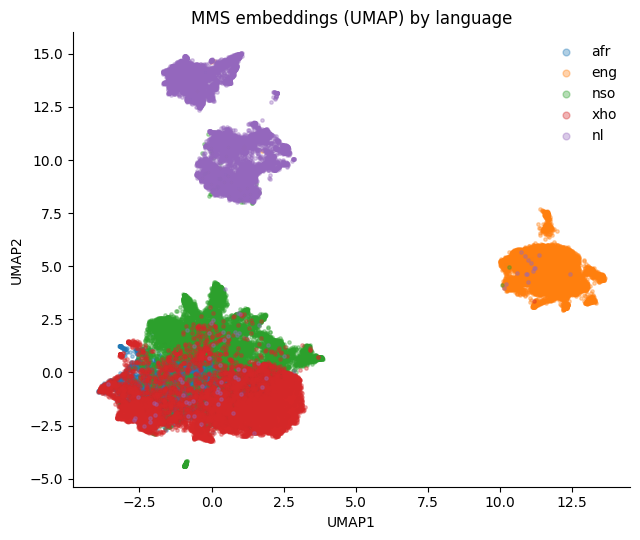

In [9]:
import umap
from sklearn.decomposition import PCA

ORDER = ["afr", "eng", "nso", "xho", "nl"]
LANG_COLORS = {
    "afr": "#1f77b4",  # blue
    "eng": "#ff7f0e",  # orange
    "nso": "#2ca02c",  # green
    "xho": "#d62728",  # red
    "nl": "#9467bd",   # purple
}
#2D UMAP of the layer 9 embeddings, coloured by language
X = np.vstack(all_child_df_best_layer["embeddings"].values)
y = all_child_df_best_layer["true_lang"].values

reducer_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                        metric="cosine", random_state=42)
XY = reducer_2d.fit_transform(X)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for lang in ORDER:
    m = y == lang
    ax.scatter(XY[m, 0], XY[m, 1], s=6, alpha=0.35,
               color=LANG_COLORS[lang], label=lang)
ax.legend(frameon=False, markerscale=2)
ax.set_title("MMS embeddings (UMAP) by language")
ax.set_xlabel("UMAP1"); ax.set_ylabel("UMAP2")
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

In [25]:
#Train the same classifier on simple low-level descriptors instead of embeddings
N_FFT = 512

#Uncomment one descriptor at a time to get each confusion matrix
def lowlevel_features(path):
    y_, sr = librosa.load(str(path), sr=SAMPLE_RATE, mono=True)
    if y_.size == 0:
        y_ = np.zeros(sr // 10)
    S = np.abs(librosa.stft(y_, n_fft=N_FFT))
    frame_rms_td = librosa.feature.rms(y=y_, frame_length=N_FFT, hop_length=N_FFT//4)[0]
    loud       = 20 * np.log10(np.sqrt(np.mean(y_ ** 2)) + 1e-8)
    noisefloor = np.percentile(20 * np.log10(frame_rms_td + 1e-8), 10)
    return np.array([
         #len(y_) / sr,
         #loud, 
         #noisefloor,
         #loud - noisefloor, 
         #librosa.feature.spectral_centroid(S=S, sr=sr).mean(),
         #librosa.feature.spectral_rolloff(S=S, sr=sr).mean(),
         librosa.feature.zero_crossing_rate(y_)[0].mean(),
    ])

# use the SAME speaker-disjoint split already built
Ftr = np.vstack([lowlevel_features(p) for p in tqdm(train_df["path"], desc="ll-train")])
Fte = np.vstack([lowlevel_features(p) for p in tqdm(test_df["path"], desc="ll-test")])
Fva = np.vstack([lowlevel_features(p) for p in tqdm(val_df["path"], desc="ll-val")])

clf_ll = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=42))
clf_ll.fit(Ftr, train_df["true_lang"].values)
y_test_pred = clf_ll.predict(Fte)
print(classification_report(test_df["true_lang"].values, y_test_pred))

clf_ll.fit(Ftr, train_df["true_lang"].values)
y_val_pred = clf_ll.predict(Fva)
print(classification_report(val_df["true_lang"].values, y_val_pred))

ll-train:   0%|          | 0/40042 [00:00<?, ?it/s]

ll-test:   0%|          | 0/5343 [00:00<?, ?it/s]

ll-val:   0%|          | 0/5040 [00:00<?, ?it/s]

              precision    recall  f1-score   support

         afr       0.17      0.09      0.12      1076
         eng       0.19      0.45      0.27      1039
          nl       0.31      0.52      0.39      1034
         nso       0.00      0.00      0.00      1148
         xho       0.20      0.11      0.14      1046

    accuracy                           0.23      5343
   macro avg       0.17      0.23      0.18      5343
weighted avg       0.17      0.23      0.18      5343

              precision    recall  f1-score   support

         afr       0.16      0.08      0.10       955
         eng       0.16      0.37      0.22      1040
          nl       0.27      0.44      0.33      1031
         nso       0.00      0.00      0.00       974
         xho       0.22      0.09      0.13      1040

    accuracy                           0.20      5040
   macro avg       0.16      0.20      0.16      5040
weighted avg       0.16      0.20      0.16      5040



/Users/conarj/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/conarj/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/conarj/Library/Python/3.9/lib/python/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(resu

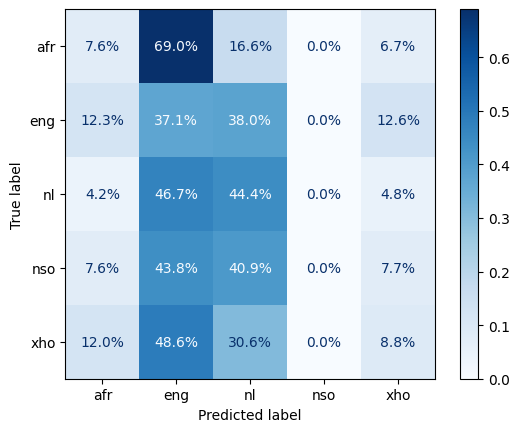

In [26]:
# Visualise the confusion matrix as percentages
#Validation set, row-normalised so each row sums to 100%
cm = confusion_matrix(
    val_df["true_lang"].values, y_val_pred,
    labels=clf_ll.classes_,
    normalize="true"          # each row sums to 1
)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf_ll.classes_)
disp.plot(cmap=plt.cm.Blues, values_format=".1%") 

In [27]:
#SNR EQUALISATION SETTINGS
SAMPLE_RATE       = 16000
FRAME_SIZE        = 512
REFERENCE_MARGIN_DB = 2.0        # reference sits slightly below Dutch so Dutch gets matched too
OUTPUT_DIR        = str(NOISY_DIR)
random_generator  = np.random.default_rng(42)

language_dataframes = {
    "Afrikaans":      afr_child_df,
    "English":        eng_child_df,
    "Xhosa":          xho_child_df,
    "Northern_Sotho": nso_child_df,
    "Dutch":          nl_child_df,
}

In [28]:
#SNR = overall level minus the noise floor (10th percentile of the frame levels)
def snr_from_waveform(waveform):
    """Estimate SNR (dB) as overall loudness minus the estimated background noise floor."""
    if waveform.size == 0:
        return np.nan

    frame_loudness = librosa.feature.rms(
        y=waveform, frame_length=FRAME_SIZE, hop_length=FRAME_SIZE // 4
    )[0]
    frame_loudness = frame_loudness[frame_loudness > 1e-6]   # drop silence / zero padding
    if frame_loudness.size == 0:
        return np.nan

    overall_loudness_db = 20 * np.log10(np.sqrt(np.mean(waveform ** 2)))
    noise_floor_db       = np.percentile(20 * np.log10(frame_loudness), 10)
    return overall_loudness_db - noise_floor_db


def load_waveform(file_path):
    """Load audio exactly the way SNR is computed, so results stay consistent."""
    waveform, _ = librosa.load(str(file_path), sr=SAMPLE_RATE, mono=True)
    return waveform


def calculate_snr(file_path):
    """Path-based wrapper for use in dataframe loops."""
    waveform = load_waveform(file_path)
    return np.array([snr_from_waveform(waveform)])

In [29]:
#SNR of every clip before any noise is added
for language_name, df in language_dataframes.items():
    utterance_snrs = [calculate_snr(p)[0] for p in tqdm(df["path"], desc=language_name)]
    df["SNR"] = utterance_snrs

    print(f"\n{language_name} SNR stats:")
    print("Mean:   ", df["SNR"].mean())
    print("Median: ", df["SNR"].median())
    print("p1:     ", df["SNR"].quantile(0.01))
    print("p5:     ", df["SNR"].quantile(0.05))
    print("p10:    ", df["SNR"].quantile(0.10))
    print("p25:    ", df["SNR"].quantile(0.25))

Afrikaans:   0%|          | 0/10085 [00:00<?, ?it/s]


Afrikaans SNR stats:
Mean:    18.116348
Median:  17.675106
p1:      3.7814288330078125
p5:      6.862822723388672
p10:     9.149525451660157
p25:     13.134063720703125


English:   0%|          | 0/10085 [00:00<?, ?it/s]


English SNR stats:
Mean:    27.756622
Median:  27.617208
p1:      18.915218200683594
p5:      21.49779853820801
p10:     22.919854736328126
p25:     25.10026741027832


Xhosa:   0%|          | 0/10085 [00:00<?, ?it/s]


Xhosa SNR stats:
Mean:    22.117422
Median:  21.876186
p1:      4.236479034423828
p5:      8.385713577270508
p10:     11.118532943725587
p25:     16.066375732421875


Northern_Sotho:   0%|          | 0/10085 [00:00<?, ?it/s]


Northern_Sotho SNR stats:
Mean:    19.608053
Median:  19.143204
p1:      6.455276412963867
p5:      9.724018859863282
p10:     11.442832946777344
p25:     14.812980651855469


Dutch:   0%|          | 0/10085 [00:00<?, ?it/s]


Dutch SNR stats:
Mean:    15.783518
Median:  14.516296
p1:      3.0648149108886718
p5:      5.4348602294921875
p10:     7.1888580322265625
p25:     10.513618469238281


In [30]:
#Dutch SNR distribution, shifted 2 dB down, is the target for every corpus
reference_snrs = np.sort(nl_child_df["SNR"].dropna().to_numpy() - REFERENCE_MARGIN_DB)

def assign_quantile_targets(snr_column, reference=reference_snrs):
    """
    Map each utterance to the reference SNR sitting at the same
    within-corpus percentile rank (e.g. this corpus's noisiest 5%
    of clips get targets from the reference's noisiest 5%).
    """
    snr_values   = snr_column.to_numpy(dtype=float)
    is_valid     = np.isfinite(snr_values)
    target_snrs  = np.full(len(snr_values), np.nan)

    ranks              = np.argsort(np.argsort(snr_values[is_valid]))
    percentile_position = (ranks + 0.5) / is_valid.sum()
    target_snrs[is_valid] = np.quantile(reference, percentile_position)

    needs_noise_removed = np.isfinite(target_snrs) & (target_snrs > snr_values)
    target_snrs[needs_noise_removed] = snr_values[needs_noise_removed]  # can't reduce noise, leave as-is

    return target_snrs, needs_noise_removed

In [31]:
#Search for the white-noise level that gives the target SNR. Noise can only lower the SNR
def add_noise_to_reach_target(waveform, target_snr_db, search_iterations=15):
    """Add white noise until snr_from_waveform(waveform) == target_snr_db."""
    if snr_from_waveform(waveform) <= target_snr_db:
        return waveform, False    # already at or below target; nothing to do

    noise_std_low, noise_std_high = 1e-7, 1.0
    #Bisection on a log scale, since the noise level can span several orders of magnitude
    for _ in range(search_iterations):
        candidate_std = np.sqrt(noise_std_low * noise_std_high)   # geometric midpoint
        candidate_noise = random_generator.normal(0, candidate_std, waveform.shape).astype(waveform.dtype)
        if snr_from_waveform(waveform + candidate_noise) > target_snr_db:
            noise_std_low = candidate_std
        else:
            noise_std_high = candidate_std

    final_std   = np.sqrt(noise_std_low * noise_std_high)
    final_noise = random_generator.normal(0, final_std, waveform.shape).astype(waveform.dtype)
    noisy_waveform = waveform + final_noise

    peak_amplitude = np.abs(noisy_waveform).max()
    if peak_amplitude > 1.0:
        noisy_waveform = noisy_waveform / peak_amplitude   # prevent clipping

    return noisy_waveform, True

In [32]:
#Write a noisy copy of every clip. Clips already below their target are copied unchanged
for language_name, df in language_dataframes.items():
    target_snrs, could_not_reach_target = assign_quantile_targets(df["SNR"])

    match_succeeded = []
    output_paths    = []

    language_output_dir = os.path.join(OUTPUT_DIR, language_name)
    os.makedirs(language_output_dir, exist_ok=True)

    file_iterator = zip(df["path"], target_snrs, could_not_reach_target)
    for file_path, target_snr, unreachable in tqdm(file_iterator, total=len(df), desc=f"Matching {language_name}"):
        base_name, extension = os.path.splitext(os.path.basename(file_path))

        if not np.isfinite(target_snr) or unreachable:
            # Leave unmatched clips as-is, but copy them in with a clear marker
            output_path = os.path.join(language_output_dir, f"{base_name}_ORIGINAL{extension}")
            shutil.copyfile(file_path, output_path)

            match_succeeded.append(False)
            output_paths.append(output_path)
            continue

        original_waveform = load_waveform(file_path)
        noisy_waveform, success = add_noise_to_reach_target(original_waveform, target_snr)

        output_path = os.path.join(language_output_dir, f"{base_name}_noisy{extension}")
        sf.write(output_path, noisy_waveform, SAMPLE_RATE)

        match_succeeded.append(success)
        output_paths.append(output_path if success else None)

    df["target_SNR"]   = target_snrs
    df["matched"]      = match_succeeded
    df["matched_path"] = output_paths

    failure_rate = 1 - np.mean(match_succeeded)
    print(f"\n{language_name}: {failure_rate:.1%} of utterances could not be matched "
          f"(original audio kept instead)")

Matching Afrikaans:   0%|          | 0/10085 [00:00<?, ?it/s]


Afrikaans: 0.2% of utterances could not be matched (original audio kept instead)


Matching English:   0%|          | 0/10085 [00:00<?, ?it/s]


English: 0.2% of utterances could not be matched (original audio kept instead)


Matching Xhosa:   0%|          | 0/10085 [00:00<?, ?it/s]


Xhosa: 0.0% of utterances could not be matched (original audio kept instead)


Matching Northern_Sotho:   0%|          | 0/10085 [00:00<?, ?it/s]


Northern_Sotho: 0.8% of utterances could not be matched (original audio kept instead)


Matching Dutch:   0%|          | 0/10085 [00:00<?, ?it/s]


Dutch: 0.0% of utterances could not be matched (original audio kept instead)


In [33]:
#SNR after matching, to check that the distributions now line up
for language_name, df in language_dataframes.items():
    snrs = [calculate_snr(p)[0] for p in tqdm(df["matched_path"], desc=language_name)]
    df["SNR"] = snrs

    print(f"\n{language_name} SNR stats:")
    print("Mean:   ", df["SNR"].mean())
    print("Median: ", df["SNR"].median())
    print("p1:     ", df["SNR"].quantile(0.01))
    print("p5:     ", df["SNR"].quantile(0.05))
    print("p10:    ", df["SNR"].quantile(0.10))
    print("p25:    ", df["SNR"].quantile(0.25))

Afrikaans:   0%|          | 0/10085 [00:00<?, ?it/s]


Afrikaans SNR stats:
Mean:    13.781064
Median:  12.509678
p1:      1.3370262145996095
p5:      3.4614830017089844
p10:     5.148064041137697
p25:     8.505664825439453


English:   0%|          | 0/10085 [00:00<?, ?it/s]


English SNR stats:
Mean:    13.777752
Median:  12.522957
p1:      1.0800595855712891
p5:      3.460808563232422
p10:     5.183710098266602
p25:     8.520639419555664


Xhosa:   0%|          | 0/10085 [00:00<?, ?it/s]


Xhosa SNR stats:
Mean:    13.786425
Median:  12.49733
p1:      1.3129186248779297
p5:      3.44997787475586
p10:     5.154340362548829
p25:     8.522405624389648


Northern_Sotho:   0%|          | 0/10085 [00:00<?, ?it/s]


Northern_Sotho SNR stats:
Mean:    13.760012
Median:  12.499908
p1:      1.0670478057861328
p5:      3.4238059997558596
p10:     5.180540466308594
p25:     8.522150039672852


Dutch:   0%|          | 0/10085 [00:00<?, ?it/s]


Dutch SNR stats:
Mean:    13.784363
Median:  12.517006
p1:      1.0749761962890625
p5:      3.444976043701173
p10:     5.1947021484375
p25:     8.50375747680664


In [ ]:
#Embeddings of the SNR-matched audio
#REGENERATE EMBEDDINGS AND SAVE :
#AFR
afr_child_df["embeddings"] = afr_child_df["matched_path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
afr_child_df.to_pickle("EMBEDDINGS/afr_child_df_normalised.pkl")

#ENG
eng_child_df["embeddings"] = eng_child_df["matched_path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
eng_child_df.to_pickle("EMBEDDINGS/eng_child_df_normalised.pkl")

#XHO
xho_child_df["embeddings"] = xho_child_df["matched_path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
xho_child_df.to_pickle("EMBEDDINGS/xho_child_df_normalised.pkl")

#NSO
nso_child_df["embeddings"] = nso_child_df["matched_path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
nso_child_df.to_pickle("EMBEDDINGS/nso_child_df_normalised.pkl")

#NLD
nl_child_df["embeddings"] = nl_child_df["matched_path"].progress_apply(
    lambda p: extract_embeddings_best_layer(p)
)
nl_child_df.to_pickle("EMBEDDINGS/nl_child_normalised.pkl")

all_child_df_best_layer = pd.concat([afr_child_df, eng_child_df, nso_child_df, xho_child_df, nl_child_df], ignore_index=True)

In [34]:
#Load the embeddings of the SNR-matched audio
afr_child_df_normalised = pd.read_pickle("EMBEDDINGS/afr_child_df_normalised.pkl")
eng_child_df_normalised = pd.read_pickle("EMBEDDINGS/eng_child_df_normalised.pkl")
xho_child_df_normalised = pd.read_pickle("EMBEDDINGS/xho_child_df_normalised.pkl")
nso_child_df_normalised = pd.read_pickle("EMBEDDINGS/nso_child_df_normalised.pkl")
nl_child_df_normalised = pd.read_pickle("EMBEDDINGS/nl_child_normalised.pkl")

all_child_df_normalised = pd.concat([afr_child_df_normalised, eng_child_df_normalised, xho_child_df_normalised, nso_child_df_normalised, nl_child_df_normalised])

In [35]:
#Same split as before, so the speakers in each set don't change
train_dfs = []
test_dfs = []
val_dfs = []

#Afrikaans :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
afr_split = next(gss1.split(afr_child_df_normalised, groups=afr_child_df_normalised["speaker"]))
afr_train_df = afr_child_df_normalised.iloc[afr_split[0]].reset_index(drop=True)
afr_temp_test = afr_child_df_normalised.iloc[afr_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
afr_val_split = next(gss2.split(afr_child_df_normalised.iloc[afr_split[1]], groups=afr_child_df_normalised.iloc[afr_split[1]]["speaker"]))
afr_val_df = afr_temp_test.iloc[afr_val_split[0]].reset_index(drop=True)
afr_test_df = afr_temp_test.iloc[afr_val_split[1]].reset_index(drop=True)

train_dfs.append(afr_train_df)
test_dfs.append(afr_test_df)
val_dfs.append(afr_val_df)

#TESTS: 
#Print all speakers in train and test set
afr_test_speakers = afr_test_df["speaker"].unique()
afr_train_speakers = afr_train_df["speaker"].unique()
afr_val_speakers = afr_val_df["speaker"].unique()

#Print number of total speakers in train and test set 
print("Afr test speakers: ", len(afr_test_speakers))
print("Afr train speakers: ", len(afr_train_speakers))  
print("Afr val speakers: ", len(afr_val_speakers))
print("Total speakers in both sets: ", len(afr_test_speakers) + len(afr_train_speakers) + len(afr_val_speakers))

#Check if any speakers are in both train and test set
for speaker in afr_test_speakers: 
    if speaker in afr_train_speakers: 
        print(f"Speaker {speaker} is in both train and test set for Afrikaans!")

#Check if any speakers are in both train and val set
for speaker in afr_val_speakers:
    if speaker in afr_train_speakers: 
        print(f"Speaker {speaker} is in both train and val set for Afrikaans!")

#Check if any speakers are in both test and val set
for speaker in afr_test_speakers:
    if speaker in afr_val_speakers: 
        print(f"Speaker {speaker} is in both test and val set for Afrikaans!")

#Print totals in train and test set
print("Afr train set total: ", len(afr_train_df))
print("Afr test set total: ", len(afr_test_df))
print("Afr val set total: ", len(afr_val_df))
print("Afr total: ", len(afr_train_df) + len(afr_test_df) + len(afr_val_df))

#English :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
eng_split = next(gss1.split(eng_child_df_normalised, groups=eng_child_df_normalised["session"]))
eng_train_df = eng_child_df_normalised.iloc[eng_split[0]].reset_index(drop=True)
eng_temp_test = eng_child_df_normalised.iloc[eng_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
eng_val_split = next(gss2.split(eng_child_df_normalised.iloc[eng_split[1]], groups=eng_child_df_normalised.iloc[eng_split[1]]["session"]))
eng_val_df = eng_temp_test.iloc[eng_val_split[0]].reset_index(drop=True)
eng_test_df = eng_temp_test.iloc[eng_val_split[1]].reset_index(drop=True)

train_dfs.append(eng_train_df)
test_dfs.append(eng_test_df)
val_dfs.append(eng_val_df)

#Xhosa : 
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
xho_split = next(gss1.split(xho_child_df_normalised, groups=xho_child_df_normalised["speaker"]))
xho_train_df = xho_child_df_normalised.iloc[xho_split[0]].reset_index(drop=True)
xho_temp_test = xho_child_df_normalised.iloc[xho_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
xho_val_split = next(gss2.split(xho_child_df_normalised.iloc[xho_split[1]], groups=xho_child_df_normalised.iloc[xho_split[1]]["speaker"]))
xho_val_df = xho_temp_test.iloc[xho_val_split[0]].reset_index(drop=True)
xho_test_df = xho_temp_test.iloc[xho_val_split[1]].reset_index(drop=True)

train_dfs.append(xho_train_df)
test_dfs.append(xho_test_df)
val_dfs.append(xho_val_df)

#Northern Sotho :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
nso_split = next(gss1.split(nso_child_df_normalised, groups=nso_child_df_normalised["speaker"]))
nso_train_df = nso_child_df_normalised.iloc[nso_split[0]].reset_index(drop=True)
nso_temp_test = nso_child_df_normalised.iloc[nso_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
nso_val_split = next(gss2.split(nso_child_df_normalised.iloc[nso_split[1]], groups=nso_child_df_normalised.iloc[nso_split[1]]["speaker"]))
nso_val_df = nso_temp_test.iloc[nso_val_split[0]].reset_index(drop=True)
nso_test_df = nso_temp_test.iloc[nso_val_split[1]].reset_index(drop=True)

train_dfs.append(nso_train_df)
test_dfs.append(nso_test_df)
val_dfs.append(nso_val_df)

#Dutch :
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
nl_split = next(gss1.split(nl_child_df_normalised, groups=nl_child_df_normalised["speaker"]))
nl_train_df = nl_child_df_normalised.iloc[nl_split[0]].reset_index(drop=True)
nl_temp_test = nl_child_df_normalised.iloc[nl_split[1]].reset_index(drop=True)
#Split the test set into validation and test set
nl_val_split = next(gss2.split(nl_child_df_normalised.iloc[nl_split[1]], groups=nl_child_df_normalised.iloc[nl_split[1]]["speaker"]))
nl_val_df = nl_temp_test.iloc[nl_val_split[0]].reset_index(drop=True)
nl_test_df = nl_temp_test.iloc[nl_val_split[1]].reset_index(drop=True)

train_dfs.append(nl_train_df)
test_dfs.append(nl_test_df)
val_dfs.append(nl_val_df)

#Create a single train, test and validation set by concatenating the individual language dataframes
train_df = pd.concat(train_dfs, ignore_index=True)
test_df = pd.concat(test_dfs, ignore_index=True)
val_df = pd.concat(val_dfs, ignore_index=True)

print(f"Train set total: {len(train_df)}")
print(f"Test set total: {len(test_df)}")
print(f"Val set total: {len(val_df)}")

print(f"Train set language distribution:\n{train_df['true_lang'].value_counts()}")
print(f"Test set language distribution:\n{test_df['true_lang'].value_counts()}")
print(f"Val set language distribution:\n{val_df['true_lang'].value_counts()}")

print("Total wavs in all sets: ", len(train_df) + len(test_df) + len(val_df))

Afr test speakers:  16
Afr train speakers:  123
Afr val speakers:  15
Total speakers in both sets:  154
Afr train set total:  8054
Afr test set total:  1076
Afr val set total:  955
Afr total:  10085
Train set total: 40042
Test set total: 5343
Val set total: 5040
Train set language distribution:
true_lang
afr    8054
nl     8020
eng    8006
xho    7999
nso    7963
Name: count, dtype: int64
Test set language distribution:
true_lang
nso    1148
afr    1076
xho    1046
eng    1039
nl     1034
Name: count, dtype: int64
Val set language distribution:
true_lang
eng    1040
xho    1040
nl     1031
nso     974
afr     955
Name: count, dtype: int64
Total wavs in all sets:  50425


In [36]:
#Retrain the classifier on the SNR-matched embeddings
#Train a lightweight classifier : 
cf = make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000, random_state=42))
train_embeddings = np.vstack(train_df["embeddings"].values)
cf.fit(train_embeddings, train_df["true_lang"].values)
y_pred = cf.predict(np.vstack(test_df["embeddings"].values))

print(classification_report(test_df["true_lang"].values, y_pred))

              precision    recall  f1-score   support

         afr       0.89      0.87      0.88      1076
         eng       0.99      1.00      0.99      1039
          nl       0.99      1.00      0.99      1034
         nso       0.95      0.89      0.92      1148
         xho       0.84      0.90      0.87      1046

    accuracy                           0.93      5343
   macro avg       0.93      0.93      0.93      5343
weighted avg       0.93      0.93      0.93      5343



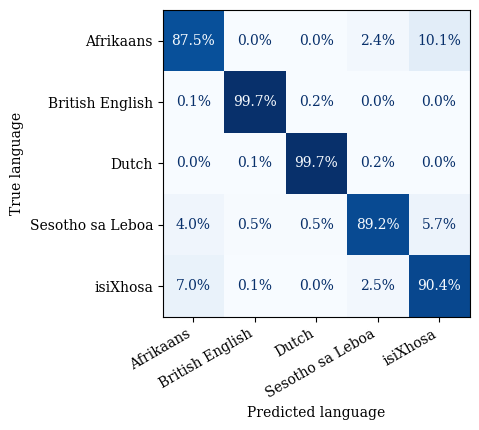

In [37]:
# Visualise the confusion matrix as percentages
LANG_NAMES = {"afr": "Afrikaans", "eng": "British English", "nl": "Dutch",
              "nso": "Sesotho sa Leboa", "xho": "isiXhosa"}

#Test set, row-normalised. Saved for Figure 6.3
cm = confusion_matrix(
    test_df["true_lang"].values, y_pred,
    labels=cf.classes_,
    normalize="true"          # each row sums to 1
)

plt.rcParams.update({"font.size": 10, "font.family": "serif"})   # matches the report's font
fig, ax = plt.subplots(figsize=(5.2, 4.4))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=[LANG_NAMES[l] for l in cf.classes_])
disp.plot(ax=ax, cmap=plt.cm.Blues, values_format=".1%", colorbar=False)

ax.set_xlabel("Predicted language")
ax.set_ylabel("True language")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()

fig.savefig("snr_matched_cm.pdf", bbox_inches="tight")            # vector, for LaTeX
fig.savefig("snr_matched_cm.png", dpi=300, bbox_inches="tight")   # high-res backup
plt.show()